In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values
from matplotlib import pyplot as plt

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Ext_Fig_09'
FIGUREDIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Let's load the sex DEGs table
fp_degs_table = OUTDIR / 'L4_multivariate_sex_edgeR_results_full.csv'
df_degs = pd.read_csv(fp_degs_table, index_col=0)
df_degs.head(3)

,logFC,logCPM,F,PValue,FDR,id
Xist,-9.366312,9.111565,693.382285,1.626745e-23,6.650134e-20,Gl4-293
Uty,6.822763,6.542082,398.997189,6.205220e-22,1.268347e-18,Gl4-293
Eif2s3y,7.544865,6.604348,321.044229,2.380016e-16,3.243169e-13,Gl4-293


In [5]:
from adjustText import adjust_text

def volcano(data: pd.DataFrame,
            logFC: str,
            p_values: str,
            x_threshold: float,
            y_threshold: float,
            ax: plt.axes,
            highlight: list | None = None,
            label_fontsize=5,
            legend_loc=None,
            up_color="#CC3232",
            down_color= "#6290E6",
            **scatter_kwargs
            ):
    
    y_threshold = -np.log10(y_threshold)

    ax.axvline(-x_threshold,color="grey",linestyle="dashed", lw=0.5)
    ax.axvline(x_threshold,color="grey",linestyle="dashed", lw=0.5)
    ax.axhline(y_threshold,color="grey",linestyle="dashed", lw=0.5)

    data = data[[logFC, p_values]].copy()
    data.loc[:, p_values] = data[p_values].apply(lambda x:-np.log10(x))
    
    data.loc[:, 'significance'] = data[logFC] * data[p_values]

    up_mask = (data[p_values] > y_threshold) & (data[logFC] > x_threshold)
    up_data = data.loc[up_mask].sort_values('significance', ascending=False)

    down_mask = (data[p_values] > y_threshold) & (data[logFC] < -x_threshold)
    down_data = data.loc[down_mask].sort_values('significance', ascending=True)
    
    print(f"{up_mask.sum()} Up, {down_mask.sum()} Down")

    other_mask = ~((down_mask) | (up_mask))
    other_data = data.loc[other_mask]

    up_texts = []

    ax.scatter(
        x=up_data[logFC],
        y=up_data[p_values],
        label="Up-regulated",
        color=up_color,
        **scatter_kwargs
    )
    if highlight:
        for i,r in up_data[up_data.index.isin(highlight)].iterrows():
            up_texts.append(
                ax.text(
                    x=r[logFC],
                    y=r[p_values],
                    s=i, 
                    fontsize=label_fontsize,
                    ha='center',
                    va='bottom',
                    bbox=dict(
                        boxstyle="round",      # Rounded box
                        facecolor="lightgrey", # Background color
                        alpha=0.8,              # Opacity (0=transparent, 1=opaque)
                        edgecolor='none'
                    )
                )
            )

    down_texts = []

    ax.scatter(
        x=down_data[logFC],
        y=down_data[p_values],
        label="Down-regulated",
        color=down_color,
        **scatter_kwargs
    )
    if highlight:
        for i,r in down_data[down_data.index.isin(highlight)].iterrows():
            down_texts.append(
                ax.text(
                    x=r[logFC],
                    y=r[p_values],
                    s=i, 
                    fontsize=label_fontsize,
                    ha='center',
                    va='bottom',
                    bbox=dict(
                        boxstyle="round",      # Rounded box
                        facecolor="lightgrey", # Background color
                        alpha=0.8,              # Opacity (0=transparent, 1=opaque)
                        edgecolor='none'
                    )
                ),
            )

    ax.scatter(
        x=other_data[logFC],
        y=other_data[p_values],
        label="Not significant",
        color="lightgrey",
        **scatter_kwargs
    )
    

    neg_x_lim = min(down_data[logFC].min()*1.25, -4) if not down_data.empty else -4
    pos_x_lim = max(up_data[logFC].max()*1.25, 4) if not up_data.empty else 4
    ax.set_xlim((neg_x_lim,pos_x_lim))
    
    neg_y_lim = 0
    pos_y_lim = data[p_values].max() * 1.3
    ax.set_ylim((neg_y_lim, pos_y_lim))

    adjust_text(up_texts,
                arrowprops=dict(
                    arrowstyle="-", 
                    ls=':', 
                    color='lightgrey', 
                    lw=0.5, 
                    shrinkA=0, 
                    shrinkB=0), 
                ax=ax,
                only_move='x+y',
                ensure_inside_axes=True,
                expand_axes=False,
                expand=(1.5, 1.2),
                prevent_crossings=False,
                max_move=(100, 100),
                min_arrow_len=1
    )
    
    adjust_text(down_texts,
                arrowprops=dict(
                    arrowstyle="-", 
                    ls=':', 
                    color='grey', 
                    lw=0.5, 
                    shrinkA=0, 
                    shrinkB=0), 
                ax=ax,
                only_move='x-y',
                ensure_inside_axes=True,
                expand_axes=False,
                expand=(1.5,1.2),
                prevent_crossings=False,
                max_move=(100,100),
                min_arrow_len=1
    )

In [6]:
from matplotlib import pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

def plot_pathway_results(data):
    n_rows = data.shape[0]

    # plt.rcParams['font.family'] = 'monospace'

    print(3.5*n_rows)
    fig, axes = plt.subplots(n_rows, 3, figsize=(45*MM, 3*MM*n_rows),
                            gridspec_kw={'width_ratios': [10, 2.5, 1], 'wspace': 0.03, 'hspace': 0.02},
                            sharey=True)
    axes = np.atleast_2d(axes)

    cmap = plt.get_cmap('YlOrRd')
    norm_pct = Normalize(vmin=0, vmax=1)
    norm_pval = Normalize(vmin=-32, vmax=16)

    for i, (_, row) in enumerate(data.iterrows()):
        ax1, ax2, ax3 = axes[i]
        
        # Name column
        s = row['name']
        if len(s) > 50:
            s = s[:44] + "..."

        # Term Name ------------------------------------------------------------------ #
        ax1.text(1, 0.5, s, va='center', ha='right', fontsize=5, weight='light')
        ax1.grid(False)
        ax1.set_ylim(0, 1)
        ax1.axis('off')
        ax1.set_xticks([])        # remove x ticks
        ax1.set_yticks([])        # remove y ticks
        ax1.spines['top'].set_visible(False)
        ax1.spines['right'].set_visible(False)
        ax1.spines['left'].set_visible(False)
        ax1.spines['bottom'].set_visible(False)
        # ax1.set_facecolor('#f0f0f0')  # keep the light grey background
        

        # Precision Indicator -------------------------------------------------------- #
        ax2.grid(False)
        ax2.set_xticks([])        # remove x ticks
        ax2.set_yticks([])        # remove y ticks
        ax2.spines['top'].set_visible(False)
        ax2.spines['right'].set_visible(False)
        ax2.spines['left'].set_visible(False)
        ax2.spines['bottom'].set_visible(False)
        
        color = cmap(norm_pct(row['precision']))
        # ax2.set_facecolor(color)  # keep the light grey background
        ax2.add_patch(Rectangle(
            (0, 0), 1, 1,
            color=color, lw=0, zorder=0
        ))
        ax2.text(0.5, 0.5, f"{row['intersection_size']}/{row['query_size']}", va='center', ha='center', fontsize=5)
        ax2.set_ylim(0,1)
        ax2.set_xlim(0,1)

        # Significance Indicator ----------------------------------------------------- #
        color = cmap(norm_pval(row['p_value']))
        ax3.barh(0.5, -np.log10(row['p_value']), color=color, height=0.6)
        ax3.grid(False)
        ax3.set_xlim(0, 11)
        if i == data.shape[0]-1:
            # ax3.xaxis.set_ticks_position('top')
            # ax3.xaxis.set_label_position('top')
            ax3.xaxis.set_tick_params(labelsize=5)
        else:
            ax3.set_xticks([])       # remove x ticks
        ax3.set_yticks([])        # remove y ticks
        ax3.spines['top'].set_visible(False)
        ax3.spines['right'].set_visible(False)
        ax3.spines['left'].set_visible(False)
        ax3.spines['bottom'].set_visible(False)
        # ax3.set_facecolor('#f0f0f0')  # keep the light grey background

    # plt.tight_layout()
    return fig

### Subplot E – Gl4-220

In [22]:
CLUSTERID = 'Gl4-220'

182 Up, 138 Down


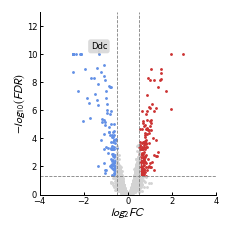

In [46]:
# Volcano plot
volcano_df = df_degs[df_degs['id'] == CLUSTERID].copy()
volcano_df['logFC'] = np.clip(-volcano_df['logFC'], -2.5, 2.5)
volcano_df['FDR'] = np.clip(volcano_df['FDR'], 1e-10, 1)

plt.close('all') # a development trick
with plt.style.context('../../../resources/figures.mplstyle') as rc:

    plt.close('all') # dev trick

    fig, ax = plt.subplots(1,1, figsize=(45*MM, 45*MM), dpi=120)

    volcano(
            data = volcano_df,
            logFC = 'logFC',
            p_values = 'FDR',
            x_threshold=0.5,
            y_threshold=0.05,
            highlight=['Ddc'],
            ax=ax,
            s = .5
        )

    # ax.tick_params(axis='both', size=0, labelsize=5, pad=1.5)
    ax.set_xlabel("$log_{2}FC$", fontsize=7)
    ax.set_ylabel("$-log_{10}(FDR)$", fontsize=7)

    ax.tick_params(labelsize=5)

    fig.subplots_adjust(bottom=0.12, top=0.98, left=0.15, right=0.98)
    fig.savefig(
        FIGUREDIR / f'subplot_e_{CLUSTERID}_volcano.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    
    plt.show();

In [32]:
# Load GO term results
fp_go_results = OUTDIR / 'GO_results' / CLUSTERID / 'results.csv'
assert fp_go_results.exists(), f'GO results yet to be computed for {CLUSTERID}'

df_go_results = pd.read_csv(fp_go_results, index_col=0)

df_go_results['-log10(pvalue)'] = -np.log10(df_go_results['p_value'])
df_go_results = df_go_results.sort_values(['highlighted', '-log10(pvalue)'], ascending=False)

df_go_results.head(2)

,description,effective_domain_size,goshv,highlighted,intersection_size,name,native,p_value,precision,query,query_size,recall,significant,source,term_size,source_order,group_id,-log10(pvalue)
0,"""The process whose specific outcome is the pro...",10899,22261,True,179,system development,GO:0048731,1.119889e-10,0.325455,query_1,550,0.087189,True,GO:BP,2053,12138,4,9.950825
19,"""The attachment of a cell, either to another c...",10899,12708,True,68,cell adhesion,GO:0007155,3.216280e-07,0.123636,query_1,550,0.121864,True,GO:BP,558,2585,5,6.492646


52.5


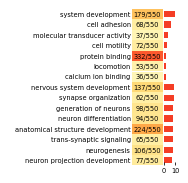

In [47]:
with plt.style.context(RCPARAMS):
    plt.close('all')
    fig = plot_pathway_results(df_go_results.head(15))
    fig.subplots_adjust(bottom=0.08, top=1, right=0.98, left=0, hspace=0, wspace=0.05)
    fig.savefig(
        FIGUREDIR / f'subplot_e_{CLUSTERID}_go.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    plt.show()

### Subplot F – Gl4-213

In [7]:
CLUSTERID = 'Gl4-213'

192 Up, 118 Down


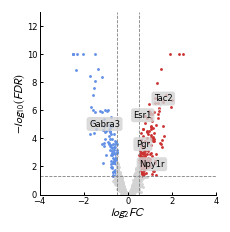

In [8]:
# Volcano plot
volcano_df = df_degs[df_degs['id'] == CLUSTERID].copy()
volcano_df['logFC'] = np.clip(-volcano_df['logFC'], -2.5, 2.5)
volcano_df['FDR'] = np.clip(volcano_df['FDR'], 1e-10, 1)

plt.close('all') # a development trick
with plt.style.context('../../../resources/figures.mplstyle') as rc:

    plt.close('all') # dev trick

    fig, ax = plt.subplots(1,1, figsize=(45*MM, 45*MM), dpi=120)

    volcano(
            data = volcano_df,
            logFC = 'logFC',
            p_values = 'FDR',
            x_threshold=0.5,
            y_threshold=0.05,
            highlight=['Pgr', 'Tac2', 'Esr1', 'Kcnip1', 'Gabra3', 'Gabre', 'Scn7a', 'Gabrb1', 'Gabrq', 'Npy1r'],
            ax=ax,
            s = .5
        )

    # ax.tick_params(axis='both', size=0, labelsize=5, pad=1.5)
    ax.set_xlabel("$log_{2}FC$", fontsize=7)
    ax.set_ylabel("$-log_{10}(FDR)$", fontsize=7)

    ax.tick_params(labelsize=5)

    fig.subplots_adjust(bottom=0.12, top=0.98, left=0.15, right=0.98)
    fig.savefig(
        FIGUREDIR / f'subplot_f_{CLUSTERID}_volcano.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    
    plt.show();

In [50]:
# Load GO term results
fp_go_results = OUTDIR / 'GO_results' / CLUSTERID / 'results.csv'
assert fp_go_results.exists(), f'GO results yet to be computed for {CLUSTERID}'

df_go_results = pd.read_csv(fp_go_results, index_col=0)

df_go_results['-log10(pvalue)'] = -np.log10(df_go_results['p_value'])
df_go_results = df_go_results.sort_values(['highlighted', '-log10(pvalue)'], ascending=False)

df_go_results.head(2)

,description,effective_domain_size,goshv,highlighted,intersection_size,name,native,p_value,precision,query,query_size,recall,significant,source,term_size,source_order,group_id,-log10(pvalue)
0,"""The process whose specific outcome is the pro...",9673,22261,True,143,system development,GO:0048731,7.907734e-11,0.362944,query_1,394,0.075661,True,GO:BP,1890,12138,4,10.101948
4,"""Any process that modulates a qualitative or q...",9673,24908,True,109,regulation of biological quality,GO:0065008,2.951434e-07,0.276650,query_1,394,0.076977,True,GO:BP,1416,14785,5,6.529967


52.5


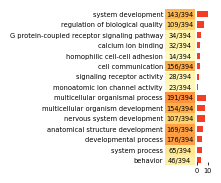

In [51]:
with plt.style.context(RCPARAMS):
    plt.close('all')
    fig = plot_pathway_results(df_go_results.head(15))
    fig.subplots_adjust(bottom=0.08, top=1, right=0.98, left=0, hspace=0, wspace=0.05)
    fig.savefig(
        FIGUREDIR / f'subplot_f_{CLUSTERID}_go.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    plt.show()

### Subplot G – Gb4-444

In [56]:
CLUSTERID = 'Gb4-444'

127 Up, 95 Down


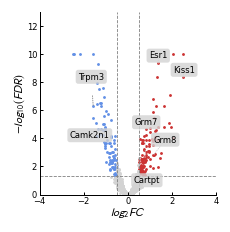

In [57]:
# Volcano plot
volcano_df = df_degs[df_degs['id'] == CLUSTERID].copy()
volcano_df['logFC'] = np.clip(-volcano_df['logFC'], -2.5, 2.5)
volcano_df['FDR'] = np.clip(volcano_df['FDR'], 1e-10, 1)

plt.close('all') # a development trick
with plt.style.context('../../../resources/figures.mplstyle') as rc:

    plt.close('all') # dev trick

    fig, ax = plt.subplots(1,1, figsize=(45*MM, 45*MM), dpi=120)

    volcano(
            data = volcano_df,
            logFC = 'logFC',
            p_values = 'FDR',
            x_threshold=0.5,
            y_threshold=0.05,
            highlight=['Esr1', 'Kiss1', 'Grm8', 'Grm7', 'Cartpt', 'Trpm3', 'Camk2n1'],
            ax=ax,
            s = .5
        )

    # ax.tick_params(axis='both', size=0, labelsize=5, pad=1.5)
    ax.set_xlabel("$log_{2}FC$", fontsize=7)
    ax.set_ylabel("$-log_{10}(FDR)$", fontsize=7)

    ax.tick_params(labelsize=5)

    fig.subplots_adjust(bottom=0.12, top=0.98, left=0.15, right=0.98)
    fig.savefig(
        FIGUREDIR / f'subplot_g_{CLUSTERID}_volcano.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    
    plt.show();

In [58]:
# Load GO term results
fp_go_results = OUTDIR / 'GO_results' / CLUSTERID / 'results.csv'
assert fp_go_results.exists(), f'GO results yet to be computed for {CLUSTERID}'

df_go_results = pd.read_csv(fp_go_results, index_col=0)

df_go_results['-log10(pvalue)'] = -np.log10(df_go_results['p_value'])
df_go_results = df_go_results.sort_values(['highlighted', '-log10(pvalue)'], ascending=False)

df_go_results.head(2)

,description,effective_domain_size,goshv,highlighted,intersection_size,name,native,p_value,precision,query,query_size,recall,significant,source,term_size,source_order,group_id,-log10(pvalue)
0,"""Any process that mediates the transfer of inf...",9473,12782,True,47,cell-cell signaling,GO:0007267,0.000001,0.182171,query_1,258,0.078595,True,GO:BP,598,2659,2,5.897414
3,"""Receiving a signal and transmitting it in the...",9473,4947,True,24,signaling receptor activity,GO:0038023,0.000207,0.093023,query_1,258,0.111111,True,GO:MF,216,4947,1,3.684067


38.5


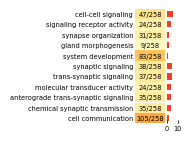

In [59]:
with plt.style.context(RCPARAMS):
    plt.close('all')
    fig = plot_pathway_results(df_go_results.head(15))
    fig.subplots_adjust(bottom=0.08, top=1, right=0.98, left=0, hspace=0, wspace=0.05)
    fig.savefig(
        FIGUREDIR / f'subplot_g_{CLUSTERID}_go.pdf',
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )
    plt.show()